In [1]:
import sys
sys.path.append('..')
import logging
logging.basicConfig(level=logging.WARN)

Interval:  9
Designing area: {'type': <CellType.Compute: 1>, 'left': 0, 'top': 0, 'right': 29, 'bottom': 9} strip 9 y
Designing area: {'type': <CellType.Compute: 1>, 'left': 0, 'top': 0, 'right': 8, 'bottom': 9} grid 4 x
Designing area: {'type': <CellType.Compute: 1>, 'left': 10, 'top': 0, 'right': 18, 'bottom': 9} grid 4 x


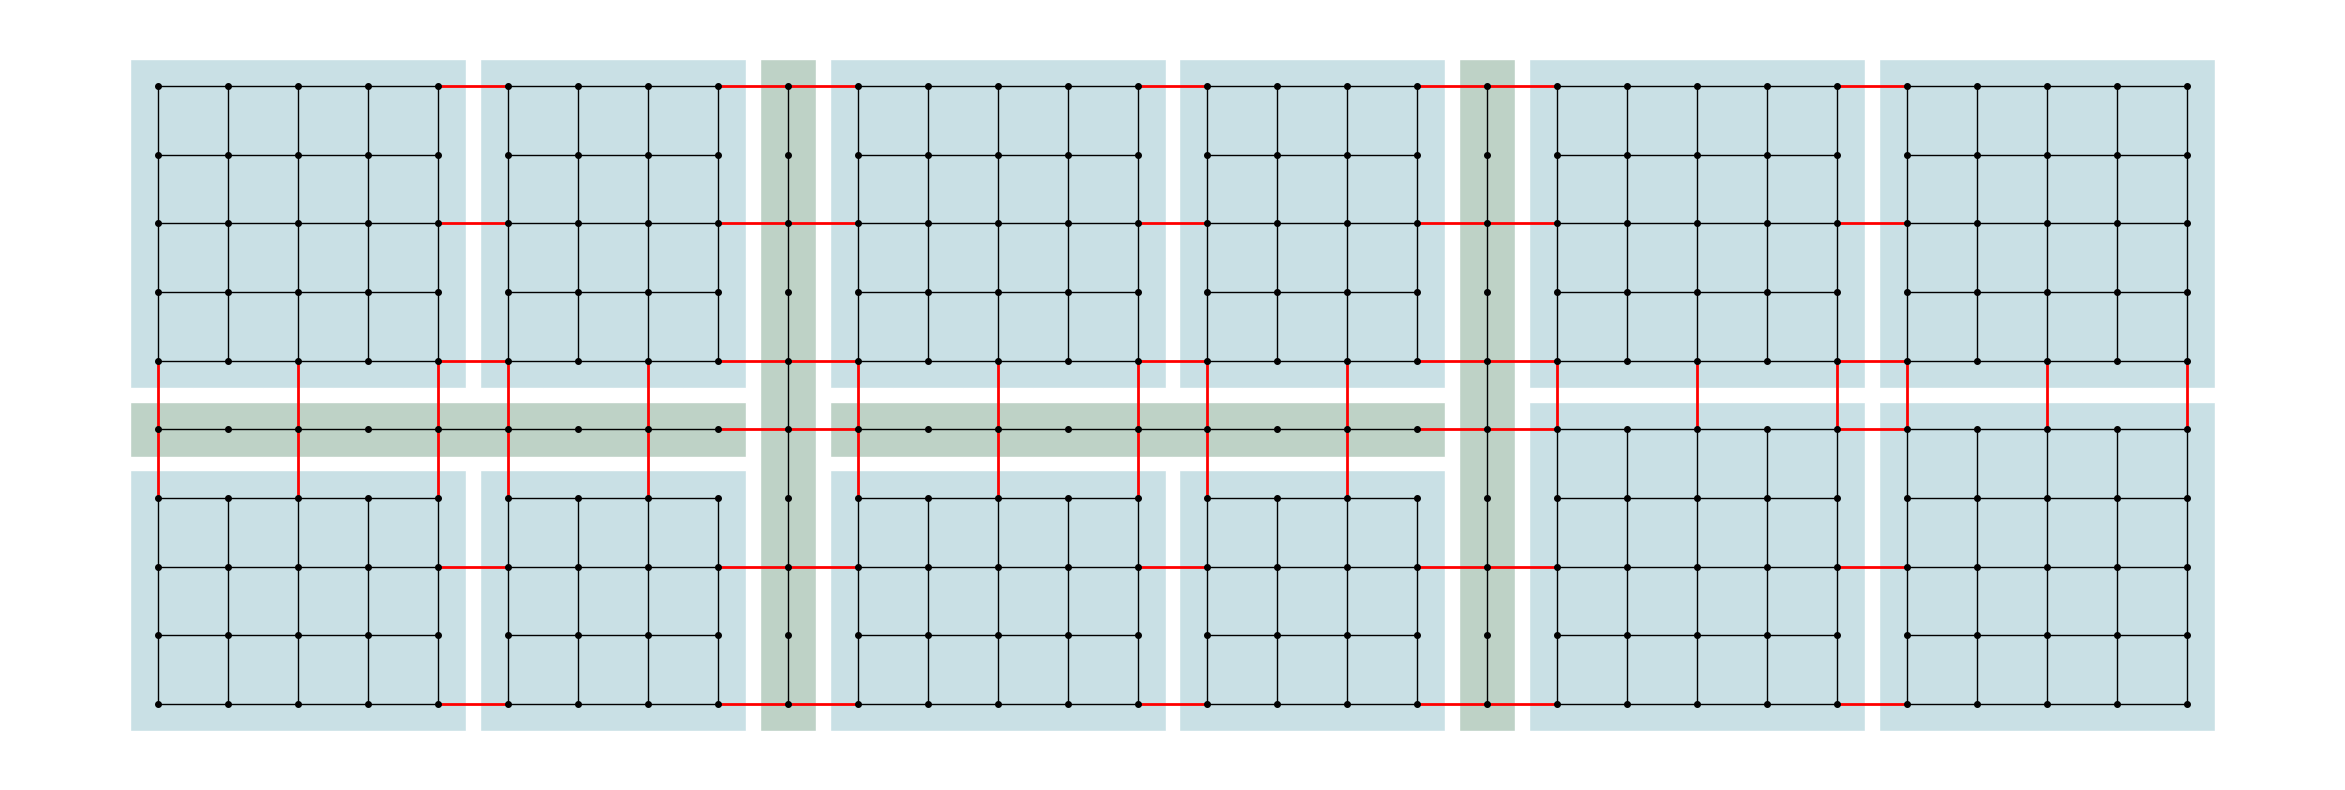

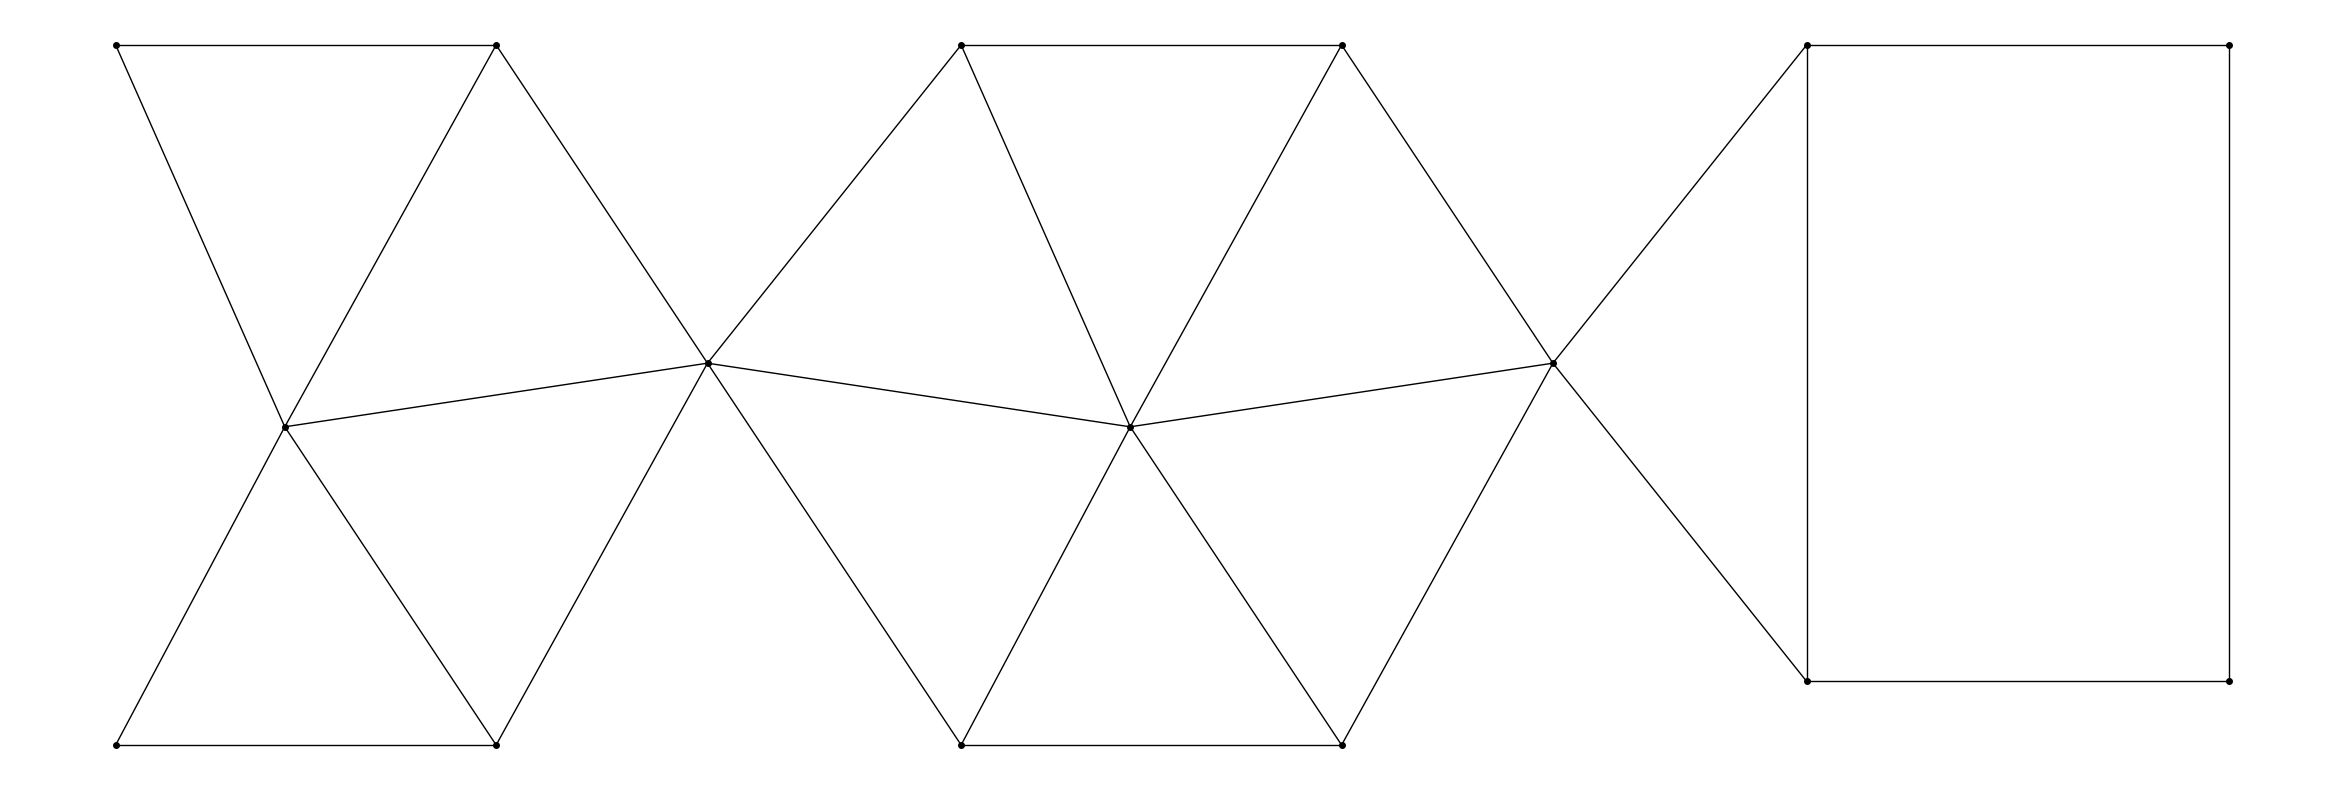

Estimated fidelity:  0.9370478422330659


In [2]:
from hyqchip.element.package import *

# fabricate_model = FabricateModel((10, 10), 50)
# package = Package((300, 100), fabricate_model)
package = Package()

package.draw_qubits()
package.draw_dies()

estimate_fide, _, _ = package.estimate_transfer()
print("Estimated fidelity: ", estimate_fide)

In [2]:
from hyqchip.element.benchmark import *

vqe_program = VQE(10)
print(f"VQE program: {vqe_program}")
qft_program = QFT(10)
print(f"QFT program: {qft_program}")
qaoa_program = QAOA(10)
print(f"QAOA program: {qaoa_program}")
bv_program = BV(10)
print(f"BV program: {bv_program}")

VQE program: ['barrier', (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), 'barrier', (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), 'barrier', (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9), 'barrier', (3, 4), (3, 5), (3, 6), (3, 7), (3, 8), (3, 9), 'barrier', (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), 'barrier', (5, 6), (5, 7), (5, 8), (5, 9), 'barrier', (6, 7), (6, 8), (6, 9), 'barrier', (7, 8), (7, 9), 'barrier', (8, 9)]
QFT program: ['barrier', [(1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0)], 'barrier', [(2, 1), (3, 1), (4, 1), (5, 1), (6, 1), (7, 1), (8, 1), (9, 1)], 'barrier', [(3, 2), (4, 2), (5, 2), (6, 2), (7, 2), (8, 2), (9, 2)], 'barrier', [(4, 3), (5, 3), (6, 3), (7, 3), (8, 3), (9, 3)], 'barrier', [(5, 4), (6, 4), (7, 4), (8, 4), (9, 4)], 'barrier', [(6, 5), (7, 5), (8, 5), (9, 5)], 'barrier', [(7, 6), (8, 6), (9, 6)], 'barrier', [(8, 7), (9, 7)], 'barrier', [(9, 8)]]
QAOA program: [(0, 9), (4, 9), (1, 2

In [ ]:
from hyqchip.layout.env import QuantumChipletEnv
from hyqchip.layout.agent import LayoutAgent
# from gymnasium.wrappers import Monitor

env = QuantumChipletEnv(package_size=(22, 11))
# env = Monitor(env, "./logs")
agent = LayoutAgent(env)

agent.train(total_timesteps=50000)
agent.save("ppo_quantum_chip_agent.zip")

print("Testing agent...")
state = env.reset()
for _ in range(1000):
    actions = agent.select_action(state)
    print("Selected Actions:", actions)
    state, reward, done, _ = env.step(actions)
    print(env.estimate())
    if done:
        break